# Interval reciprocal QSVT

An odd polynomial approximates a scaled inverse across a promised signed Hermitian spectrum. The input is an explicit Pauli matrix and a reproducible gate-built complex vector. Matrix-access PREPARE/SELECT/unprepare and projector phases are actual gates. Dense spectral analysis and a classical solve appear only as independent small-instance references.

This notebook reuses original MIT implementation code and records exact rational polynomial facts separately from phase, access and synthesis errors. It uses the pinned Qiskit/NumPy/SciPy environment. Saved outputs can be published statically; optional live controls require a Python kernel.

In [1]:
from pathlib import Path
from fractions import Fraction
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
root = Path.cwd()
if not (root/'src/openquantum/linear_systems_qsvt_reciprocal.py').exists() and (root.parent/'src/openquantum/linear_systems_qsvt_reciprocal.py').exists():
    root = root.parent
if (root/'src/openquantum/linear_systems_qsvt_reciprocal.py').exists():
    sys.path.insert(0, str(root/'src'))
elif (root/'code/src/openquantum/linear_systems_qsvt_reciprocal.py').exists():
    sys.path.insert(0, str(root/'code/src'))
from openquantum import linear_systems_qsvt_reciprocal as inv
from openquantum.reciprocal_phase_certificate import certify_real_qsp_phases
terms = inv.DEFAULT_TERMS
K = inv.choose_k('1/2', '.01')
model = inv.ReciprocalPolynomial(K, Fraction(1,2))
prep = inv.default_preparation(2)
print('Explicit input:', terms)
print('K, odd degree, scale:', K, model.degree, model.scale)
print('Promised signed interval: 1/2 <= |lambda(A/alpha)| <= 1')

Explicit input: ((15, 'II'), (-2, 'IX'), (-2, 'ZI'), (-1, 'XX'))
K, odd degree, scale: 16 33 1/5
Promised signed interval: 1/2 <= |lambda(A/alpha)| <= 1


## Reciprocal approximation across an interval

With $m=K+1$ and $c=1/\lceil\sqrt m\rceil$,

$$p_K(x)=c\,x\sum_{j=0}^{K}(1-x^2)^j.$$

It is odd and bounded by one across $[-1,1]$. On a promised spectrum $\delta\le|x|\le1$, relative inverse error is at most $E=(1-\delta^2)^m$. The positive relative factor has eigenvalues in $[1-E,1]$, giving normalized-state trace distance $E/(2-E)$ and Pauli-mean bias $2E/(2-E)$.

The degree is $O(\delta^{-2}\log(1/\epsilon_A))$ for a Pauli-bias target $\epsilon_A$. This original geometric polynomial does not achieve the optimal condition dependence of more advanced QSVT reciprocal approximations.

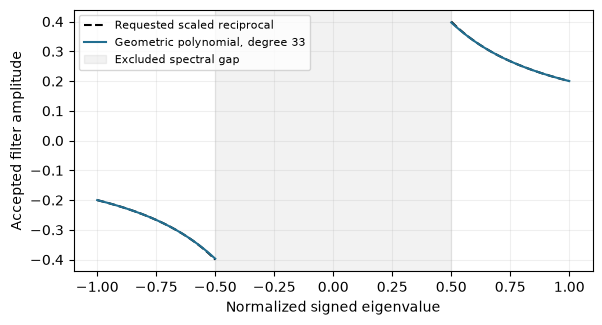

,degree,relative tail bound,scaled operator error bound,conditional trace bound,conditional Pauli bias bound,target acceptance lower bound
0,33,0.007517,0.003007,0.003773,0.007545,0.04


In [2]:
fig, ax = plt.subplots(figsize=(6.7,3.4))
for interval in ((-1.,-.5),(.5,1.)):
    grid = np.linspace(*interval,401)
    ax.plot(grid, float(model.scale)/grid, '--', color='black',
            label='Requested scaled reciprocal' if interval[0]>0 else None)
    ax.plot(grid, inv.reciprocal_polynomial(grid,K), color='#216e90',
            label=f'Geometric polynomial, degree {model.degree}' if interval[0]>0 else None)
ax.axvspan(-.5,.5,alpha=.1,color='gray',label='Excluded spectral gap')
ax.set(xlabel='Normalized signed eigenvalue',ylabel='Accepted filter amplitude')
ax.grid(alpha=.2); ax.legend(fontsize=8); plt.show()
display(pd.DataFrame([{
    'degree': model.degree,
    'relative tail bound': float(model.relative_tail),
    'scaled operator error bound': model.as_metadata()['scaled_inverse_operator_error_bound'],
    'conditional trace bound': float(model.trace_bound),
    'conditional Pauli bias bound': float(model.pauli_bias_bound),
    'target acceptance lower bound': float(model.success_lower_bound)
}]))

## Small actual circuit

A readable coarse demonstration uses one data qubit, $A=3I-X$, normalization four and promised gap one-half. Setting $K=1$ gives degree three. The circuit below contains the actual positive-amplitude loading, signed Pauli SELECT, unprepare, real-part flag and all final measurements. This is a lower-accuracy demonstration; the default degree33 circuit is checked separately.

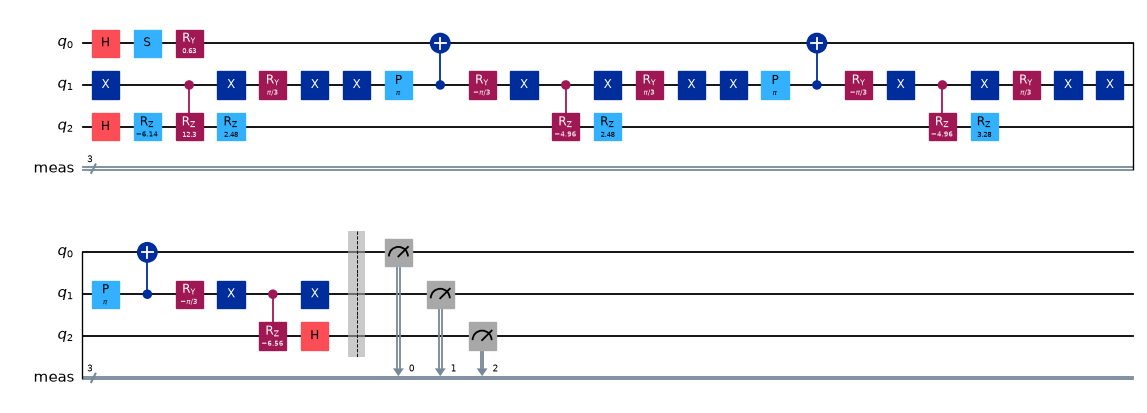

Small actual acceptance: 0.22070312499999944
Small Z bias / bound: 4.440892098500626e-16 0.782608695652174


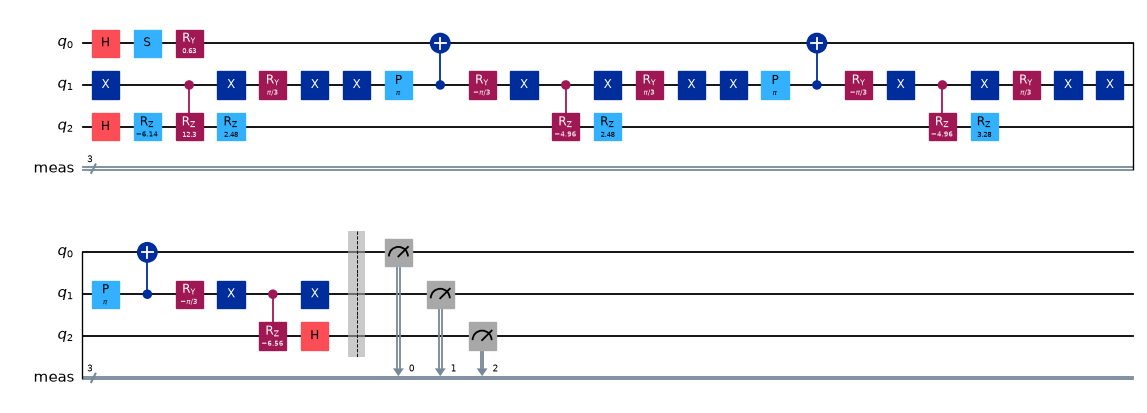

In [3]:
small_terms = ((3,'I'),(-1,'X'))
small = inv.measured_reciprocal_trial(small_terms,k=1,delta='1/2',preparation=inv.default_preparation(1))
display(small.draw(output='mpl',fold=25,scale=.65))
small_result = inv.compare_reciprocal(small_terms,k=1,delta='1/2',preparation=inv.default_preparation(1))
print('Small actual acceptance:',small_result['success_probability'])
print('Small Z bias / bound:',small_result['z_absolute_bias'],small_result['analytic_Pauli_bias_bound'])

## Default source and complete readout

The two-qubit default $A=15II-2IX-2ZI-XX$ has four distinct eigenvalues. H, S, RY and CX gates prepare a complex entangled input independently of the solution. The degree33 source contains 33 complete matrix-access calls and 34 projector phases. The compact gate below has those actual definitions; the exported measured QASM contains primitive operations.

All data, label and flag bits are measured. Acceptance checks only zero labels and zero flag. Final X readout adds H; Y readout adds S-dagger then H. Every failed attempt incurs the complete preparation/access/readout schedule.

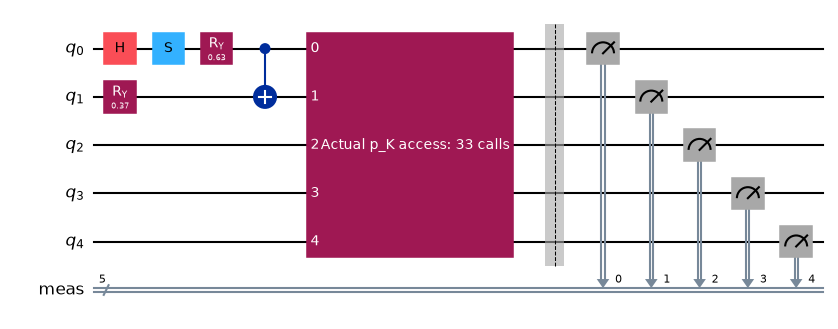

Data / labels / flag: 2 2 1
Access calls / projector phases: 33 34


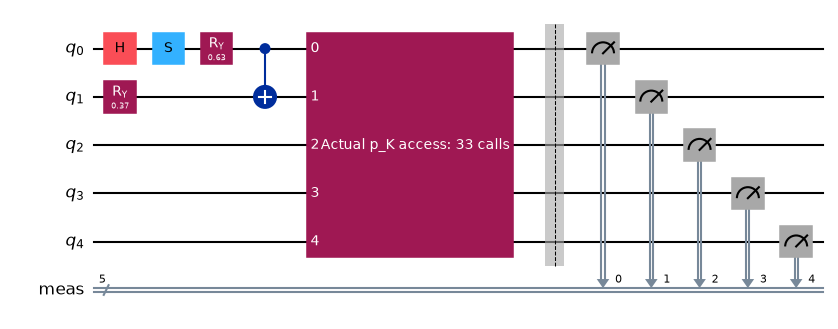

In [4]:
source = inv.build_reciprocal_qsvt(terms,K,'1/2')
default_trial = inv.measured_reciprocal_trial(terms,K,'1/2',prep)
compact = QuantumCircuit(source.num_qubits)
compact.compose(prep,qubits=range(2),inplace=True)
compact.append(source.to_gate(label=f'Actual p_K access: {model.degree} calls'),range(source.num_qubits))
compact.measure_all()
display(compact.draw(output='mpl',fold=30,scale=.75))
print('Data / labels / flag:',source.metadata['n_system'],source.metadata['n_index'],source.metadata['n_flag'])
print('Access calls / projector phases:',source.metadata['block_encoding_calls'],source.metadata['projector_phase_calls'])

In [5]:
result = inv.compare_reciprocal(terms,K,'1/2',prep)
assert result['accepted_branch_error_vs_target_polynomial'] < 1e-11
assert result['solution_trace_distance'] <= result['analytic_trace_bound']+1e-11
assert result['z_absolute_bias'] <= result['analytic_Pauli_bias_bound']+2e-11
assert result['success_probability'] >= result['analytic_success_lower_bound']-1e-11
display(pd.DataFrame([{
    'actual condition':result['actual_condition_number'],
    'actual acceptance':result['success_probability'],
    'branch error vs target polynomial':result['accepted_branch_error_vs_target_polynomial'],
    'solution trace distance':result['solution_trace_distance'],
    'Z from circuit':result['z_actual'],
    'Z from independent solve':result['z_classical_solution'],
    'Z bias':result['z_absolute_bias'],
    'uniform Pauli bias bound':result['analytic_Pauli_bias_bound']
}]))
print('Normalized eigenvalues:',result['normalized_eigenvalues'])

,actual condition,actual acceptance,branch error vs target polynomial,solution trace distance,Z from circuit,Z from independent solve,Z bias,uniform Pauli bias bound
0,1.787086,0.082254,2.344825e-15,0.001494,0.232102,0.232949,0.000847,0.007545


Normalized eigenvalues: [0.5381966011250103, 0.7381966011250104, 0.7618033988749894, 0.9618033988749897]


## Numerical phase evidence and a rigorous ideal-signal certificate

The stored binary phases are treated as exact real numbers by a separate rational certificate. Taylor bounds enclose their complex exponentials, an exact polynomial recurrence reconstructs the real response, and the Chebyshev coefficient one-norm bounds the difference on every $x\in[-1,1]$. The certificate covers the ideal scalar signal sequence. It does not cover floating PREPARE angle construction, compiler errors, physical synthesis or faults.

The dense grid and floating coefficient fit below are independent numerical evidence, rather than the source of the uniform certificate.

In [6]:
phase_record = inv.verify_reciprocal_phases(K,inv.DEFAULT_PHASES)
certificate = certify_real_qsp_phases(inv.DEFAULT_PHASES,inv.exact_chebyshev_coefficients(K))
adjusted = inv.phase_adjusted_bounds(model,certificate)
display(pd.DataFrame([{
    'dense-grid phase error':phase_record['dense_grid_max_error'],
    'numerical coefficient L1 discrepancy':phase_record['numerical_coefficient_l1_discrepancy'],
    'rigorous uniform ideal-phase error upper':certificate.float_upper_bound,
    'phase-adjusted ideal Pauli bias bound':adjusted['phase_adjusted_Pauli_bias_bound'],
    'phase-adjusted ideal acceptance lower':adjusted['phase_adjusted_success_lower_bound']
}]))
print('Certificate scope:',certificate.as_metadata()['verification_scope'])
print('Excluded:',certificate.as_metadata()['excluded_errors'])

,dense-grid phase error,numerical coefficient L1 discrepancy,rigorous uniform ideal-phase error upper,phase-adjusted ideal Pauli bias bound,phase-adjusted ideal acceptance lower
0,4.662937e-15,7.162293e-15,5.475706e-15,0.007545,0.04


Certificate scope: rigorous rational bound for the ideal signal sequence with exact stored binary phases
Excluded: ['matrix loading/access', 'gate decomposition or compiler', 'concrete angle synthesis', 'physical faults']


## Signed spectrum and degree convergence

The same odd transformation supports an indefinite Hermitian matrix. Here $A=7ZI+2IZ+XX$, $\alpha=10$ has eigenvalues $\pm\sqrt{.26},\pm\sqrt{.82}$. The input remains gate-built and complex. Increasing degree reduces the target approximation error at a fixed promised gap; those extra access and projector operations are paid by the quantum circuit.

,signed eigenvalues,acceptance,branch error vs polynomial,solution trace distance
0,"[-0.905539, -0.509902, 0.509902, 0.905539]",0.052273,2.580784e-15,0.001792


,K,degree,actual Z bias,uniform Z bias bound,actual acceptance
0,0,1,0.470539,1.200000,0.588616
1,1,3,0.284657,0.782609,0.260860
2,3,7,0.106649,0.375870,0.390597
3,7,15,0.020419,0.105388,0.214936
4,12,25,0.003375,0.024043,0.127432
5,16,33,0.000847,0.007545,0.082254


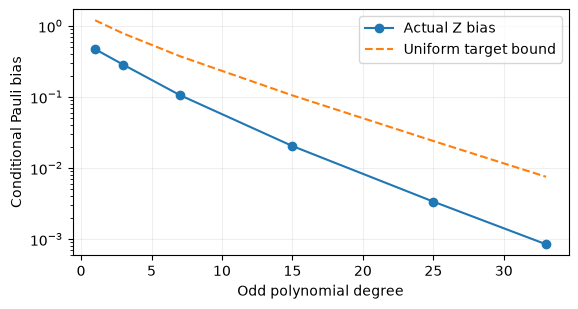

In [7]:
signed = inv.compare_reciprocal(((7,'ZI'),(2,'IZ'),(1,'XX')),K,'1/2',prep)
display(pd.DataFrame([{'signed eigenvalues':signed['normalized_eigenvalues'],
                       'acceptance':signed['success_probability'],
                       'branch error vs polynomial':signed['accepted_branch_error_vs_target_polynomial'],
                       'solution trace distance':signed['solution_trace_distance']}]))
rows=[]
for chosen_k in (0,1,3,7,12,16):
    chosen_phases = inv.DEFAULT_PHASES if chosen_k==K else inv.fit_reciprocal_phases(chosen_k)[0]
    check = inv.compare_reciprocal(terms,chosen_k,'1/2',prep,chosen_phases)
    rows.append({'K':chosen_k,'degree':2*chosen_k+1,
                 'actual Z bias':check['z_absolute_bias'],
                 'uniform Z bias bound':check['analytic_Pauli_bias_bound'],
                 'actual acceptance':check['success_probability']})
convergence = pd.DataFrame(rows)
display(convergence)
fig,ax=plt.subplots(figsize=(6.4,3.2))
ax.semilogy(convergence['degree'],convergence['actual Z bias'],'o-',label='Actual Z bias')
ax.semilogy(convergence['degree'],convergence['uniform Z bias bound'],'--',label='Uniform target bound')
ax.set(xlabel='Odd polynomial degree',ylabel='Conditional Pauli bias')
ax.grid(alpha=.2);ax.legend();plt.show()

## Complete logical cost and proposed repetitions

The requested conditional Pauli mean has an absolute-error allocation .05: .01 algorithm bias, .01 synthesis bias and .03 statistical error. Separate failure allocations are .004 sampling, .001 empty accepted slot and .005 physical faults. The stored-phase certificate slightly reduces the ideal acceptance bound before retry selection. It still does not certify the floating access angles or physical circuit.

For $N$ accepted slots and at most $R$ complete fresh trials per slot, empty-slot failure is at most $N(1-p)^R$. Hoeffding sampling and this finite-cap condition determine an unexecuted ideal workload proposal. Every rejected trial pays all preparation, access, measurement and reset assumptions. Lowering preserves arbitrary coherent inputs by disabling the initially-zero simplification.

In [8]:
compiled = inv.lower_reciprocal(default_trial)
workload = inv.observable_workload(Fraction(adjusted['retry_success_lower_bound_exact']))
counts = dict(compiled.count_ops())
display(pd.DataFrame([{
    'logical qubits':compiled.num_qubits,
    'CX per complete attempt':counts.get('cx',0),
    'continuous rotations per attempt':sum(counts.get(g,0) for g in ('rx','ry','rz')),
    'all measurements per attempt':counts.get('measure',0),
    'dependency depth':compiled.depth(),
    'accepted slots proposal':workload['accepted_samples'],
    'retry cap per slot proposal':workload['retry_cap_per_slot'],
    'total capped complete attempts':workload['total_capped_attempts']
}]))
print('Verified empty-slot union bound:',workload['verified_union_empty_slot_bound'])
print('Ideal uncapped expected attempts upper:',workload['uncapped_expected_attempts_upper'])
print('Workload scope:',workload['assumptions'])
print('Recorded compiled global phase:',float(compiled.global_phase))

,logical qubits,CX per complete attempt,continuous rotations per attempt,all measurements per attempt,dependency depth,accepted slots proposal,retry cap per slot proposal,total capped complete attempts
0,5,1391,1756,5,2685,13811,403,5565833


Verified empty-slot union bound: 0.0009897648813940699
Ideal uncapped expected attempts upper: 345275.00000003807
Workload scope: independent fresh preparation, exact target acceptance lower bound; access/phase/synthesis changes require a revised lower bound
Recorded compiled global phase: 1.5707963267948095


In [9]:
physical_path = root/'assets/generated/linear-systems/reciprocal-qsvt/surface-code.json'
if physical_path.exists():
    physical = json.loads(physical_path.read_text())
    points = physical.get('pareto_points',[])
    if points:
        display(pd.DataFrame([{
            'peak physical qubits':p['peak_physical_qubits'],
            'data code distance':p['data_code_distance'],
            'T factories':p['factories']['T']['copies'],
            'seconds per complete attempt':p['runtime_per_execution_ns']/1e9,
            'serial days for capped workload':p['serial_runtime_all_executions_ns']/1e9/86400
        } for p in points]))
        print('Physical model:',physical['physical_profile'])
        print('Status:',physical['resource_estimate_kind'])
    else:
        print('Physical projection unavailable:',physical.get('status'))
else:
    print('Generate the separate surface-code report to inspect physical costs; it is not recomputed here.')

,peak physical qubits,data code distance,T factories,seconds per complete attempt,serial days for capped workload
0,283752,25,10,0.228150,14.697278
1,306423,23,11,0.209898,13.521496
2,329382,21,12,0.191646,12.345713
3,349278,19,15,0.173394,11.169931
4,391526,17,17,0.155142,9.994149
5,434062,15,19,0.136890,8.818367
6,499306,13,22,0.118638,7.642584


Physical model: {'name': 'illustrative-p-1e-4', 'physical_error_rate': 0.0001, 'gate_time_ns': 100, 'measurement_time_ns': 500}
Status: conditional_mean_fit_resource_projection


The separate QDK surface-code report is a conditional projection at the frozen illustrative physical parameters. Its mean-fit synthesis scalar does not prove postselected-output accuracy. Clean initialization timing/faults and classical preparation/compilation/reference/readout timing are excluded. Measured QASM may omit its recorded global phase; it is not a phase-preserving controlled inverse oracle. No integrated Lean formalization currently covers these gates.

The scalable generator uses $A_n=3R I-\sum Z_i-\sum X_iX_{i+1}$, $R=2n-1$, $\alpha=4R$, with every spin active and a coefficient-norm gap promise one-half. Circuit generation is bounded separately from statevector/reference execution.

## Optional live exploration

Live controls change degree on a bounded two-qubit system. Static publication preserves the executed outputs and skips these controls; no maintained backend is needed for reading the book.

In [10]:
if not os.environ.get('OPENQUANTUM_STATIC_BUILD'):
    import ipywidgets as widgets
    def explore(chosen_k=16):
        phases = inv.DEFAULT_PHASES if chosen_k==16 else inv.fit_reciprocal_phases(chosen_k)[0]
        check = inv.compare_reciprocal(terms,chosen_k,'1/2',prep,phases)
        display(pd.DataFrame([{'degree':2*chosen_k+1,'actual Z bias':check['z_absolute_bias'],
                               'uniform Z bias bound':check['analytic_Pauli_bias_bound'],
                               'actual acceptance':check['success_probability']}]))
    display(widgets.interactive(explore,chosen_k=widgets.SelectionSlider(options=[0,1,3,7,12,16],value=16)))